<a href="https://colab.research.google.com/github/SarahAbuirmeileh/PyTorch_Learning/blob/01-PyTorch-Workflow-Fundamentals/01_PyTorch_Workflow_Fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PyTorch Workflow

In [2]:
what_we_are_covring = {
    1: "data (prepare and load)",
    2: "build model",
    3: "fitting the model to data (training)",
    4: "making predictions and evaluating a model (inference)",
    5: "saving and loading a model",
    6: "putting it all together"
}

In [3]:
import torch
from torch import nn # it has all building blocks for neural network

import matplotlib.pyplot as plt

## 1. Data prepration and loading

**Data can be from any type**
1. Excel sheet
2. images
3. videos
4. Audio
5. DNA
6. Text


**Machine learning is a game of two parts:**
1. Get data into numerical representation.
2. Build a model to learn patterns from these numirical representation.

In [4]:
# Create a linear regression formula to make a straight line with known parameters
# The equation formula is Y = a + bX
# a -> intercept (bais)
# b -> slop (weight)

weight = 0.7
bias = 0.3

# We want to create a model to predict these numbers
start = 0
end = 1
step = 0.02

# X -> input
X = torch.arange(start, end, step).unsqueeze(dim=1)
# y -> output
y = bias + weight * X

# in the real senarios bais, weight are unknown, but here just an example
print(X[: 10])
print(y[:10])


tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800]])
tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
        [0.3700],
        [0.3840],
        [0.3980],
        [0.4120],
        [0.4260]])


## Splitting data into traning and testing (one of the most important concepts in ML)
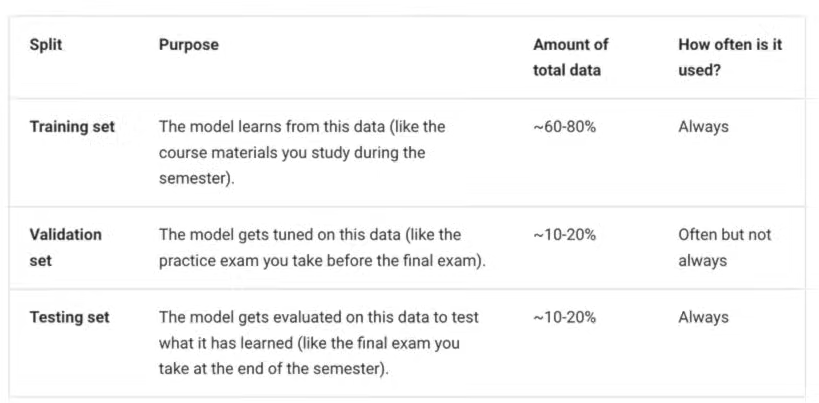

In [5]:
# Create a train split
# it's common to have 80% / 20% for trainign and testing
train_split = int(0.8 * len(X))
train_split
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

## How might we better visualize our data?
**Via explorers motto !**

In [6]:
def plot_predictions(train_data = X_train,
                     train_labels = y_train,
                     test_data = X_test,
                     test_labels = y_test,
                     predictions = None):
  """
  plot train data, test data and compares predictions
  """
  plt.figure(figsize=(10,7))

  # plot traning data in blue
  # c is for color, b is for blue
  plt.scatter(train_data, train_labels, c='b', s=4, label="training data")

  # plot test data in green
  plt.scatter(test_data, test_labels, c='g', s=4, label="testing data")

  # is there predications?
  if predictions is not None:
    plt.scatter(test_data, predictions, c='r', s=4, label="prediction data")

  # this is for
  plt.legend(prop={"size": 14});




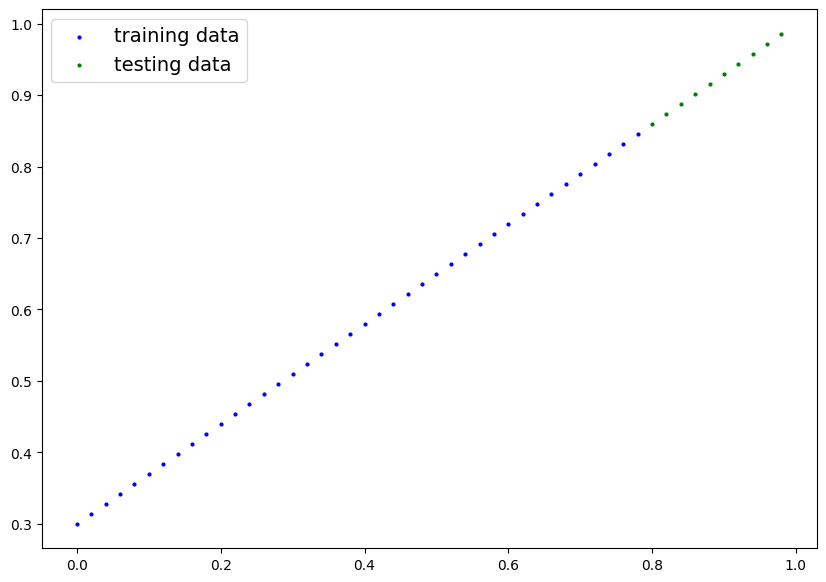

In [7]:
plot_predictions()

 ## Build model (to learn the patterns and get predictions)

** What our model do ?**
1. start with random values (wieghts and bais)
2. Look at the traning data and adjust the values to better represents the data.
`Get closer (if not ideal) to the original wieghts and bais that we used to create the data`

**how to do so?**
1. Grediant descent (uses the gradients to update those parameters.)
2. Backpropagation (calculates the gradients)

Note -> Gradient: tells us how the loss changes when a parameter changes.

## Pytorch building model essentionals:
1. torch.nn -> contains all build block for neural networks
2. t,rch.nn.Parameter -> what paramters should our model try and learn, ofter a pytorch layer (from torch.nn) will set these for us
3. torch.nn.Module -> the bais class for all neural network, if you subclass it, you must override the forward() method
4. torch.optim -> where the optimizeres in pytorch are, it helps in gradient descent
5. forword() -> defins what happen in the forword computations
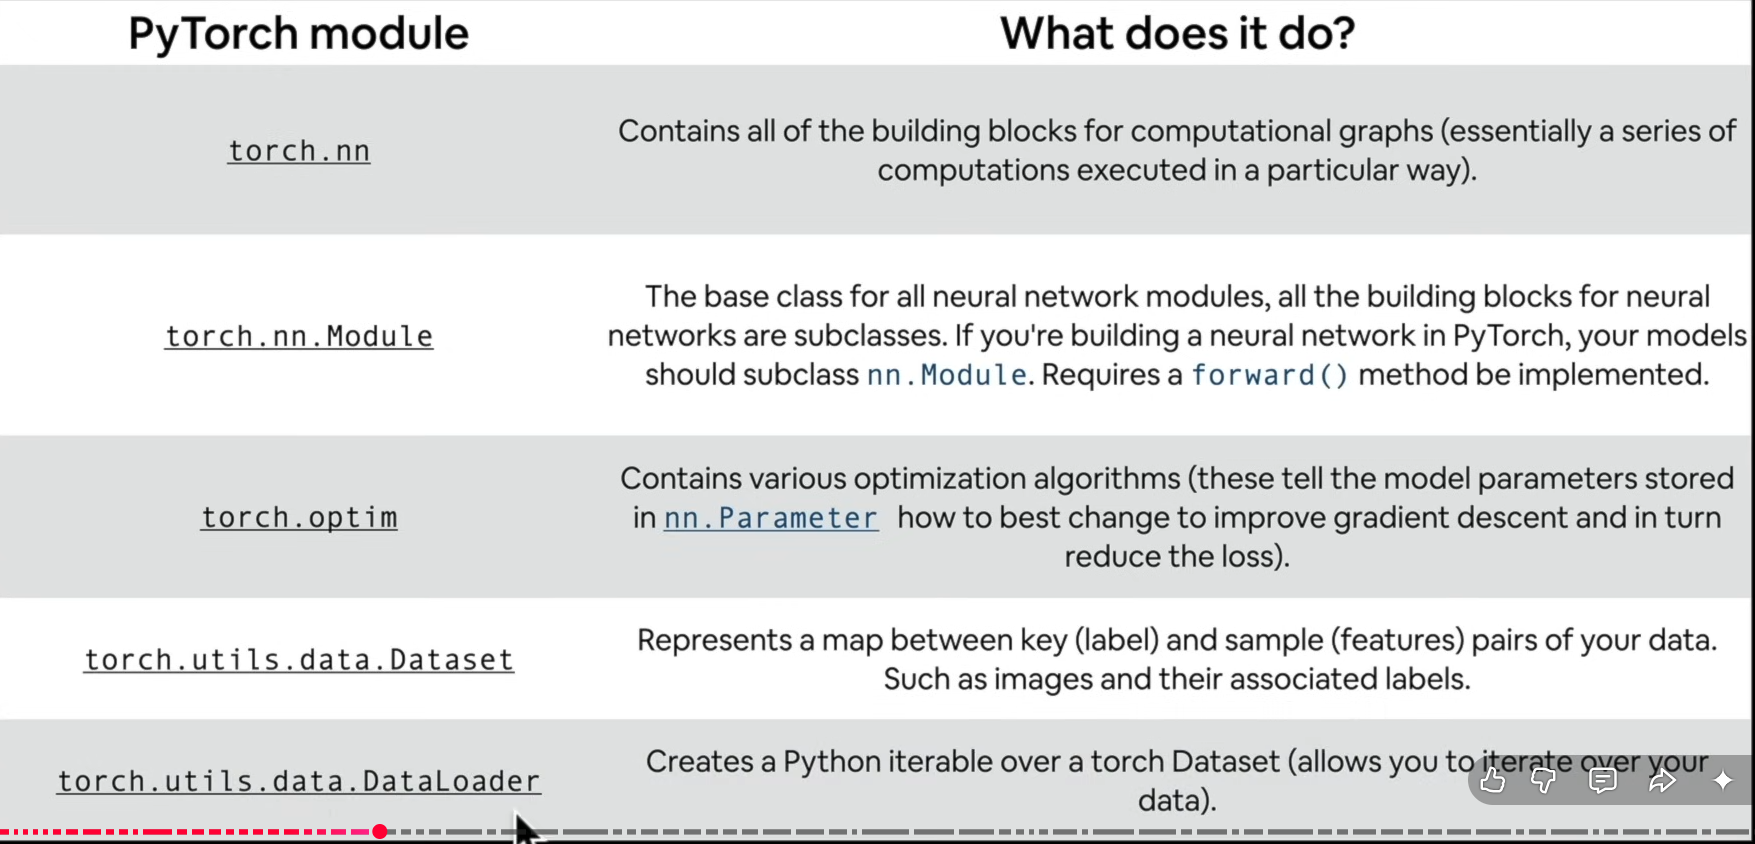

In [8]:
# Create a liner regrision model class

class LinearRegressionModel(nn.Module): # almost everything in pytorch inhiret this module
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.rand(1,
                                           requires_grad=True,
                                           dtype=torch.float))

    self.bais = nn.Parameter(torch.rand(1,
                                        requires_grad=True,
                                        dtype=float))

  # Fowrward method: te define the computation in the model
  def forward(self, x: torch.Tensor) -> torch.Tensor :
      # x is the input data (training data)
    return self.weights * x + self.bais # This is the lienar regression formula

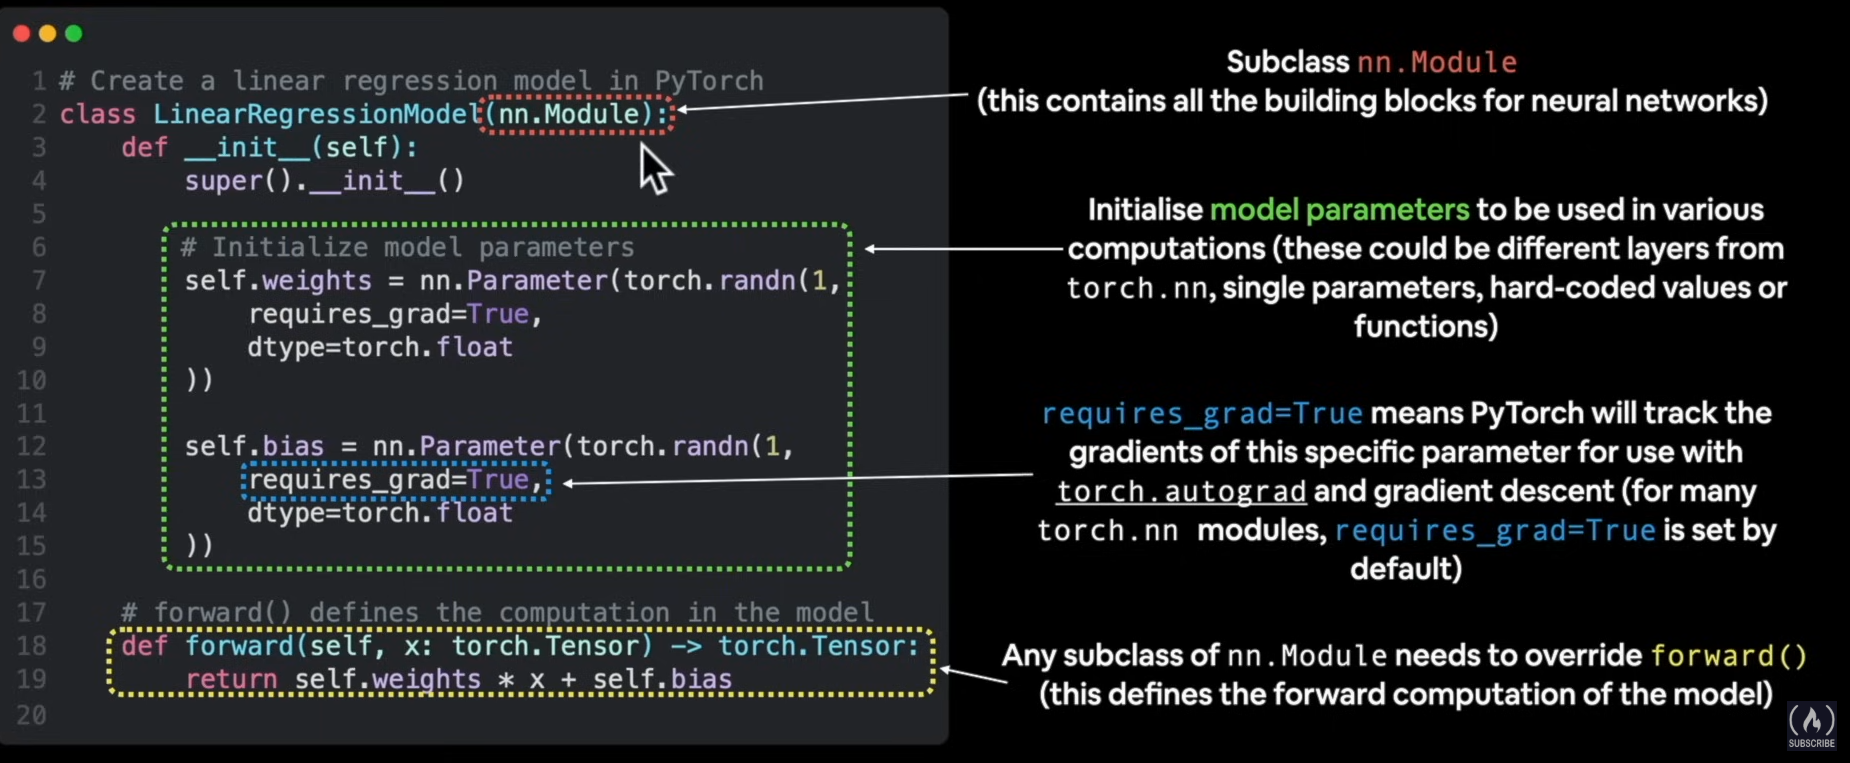

In [9]:
# Check the content of out model, via .parameter()

# 1. create a random seed
torch.manual_seed(42)

# 2. create an instance of out model
model_0 = LinearRegressionModel()
# lsit the paramrters values
list(model_0.parameters())


[Parameter containing:
 tensor([0.8823], requires_grad=True),
 Parameter containing:
 tensor([0.3200], dtype=torch.float64, requires_grad=True)]

In [10]:
# list the parameter names as dicetionaty
model_0.state_dict()

OrderedDict([('weights', tensor([0.8823])),
             ('bais', tensor([0.3200], dtype=torch.float64))])

In [11]:
# make a predection
# how good is out model in predicting x_test to y_test

with torch.inference_mode():
  y_preds = model_0(X_test)
y_preds

# This is similer to:
# y_preds = model_0(X_test)
# but this keep trackign the greadints, in the infrence node it is not -> which mean faster computations

# We can do sth similer :
# with torch.no_grad():
# but infrence mode is the best one !

tensor([[1.0258],
        [1.0435],
        [1.0611],
        [1.0788],
        [1.0964],
        [1.1141],
        [1.1317],
        [1.1494],
        [1.1670],
        [1.1847]], dtype=torch.float64)

In [12]:
y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

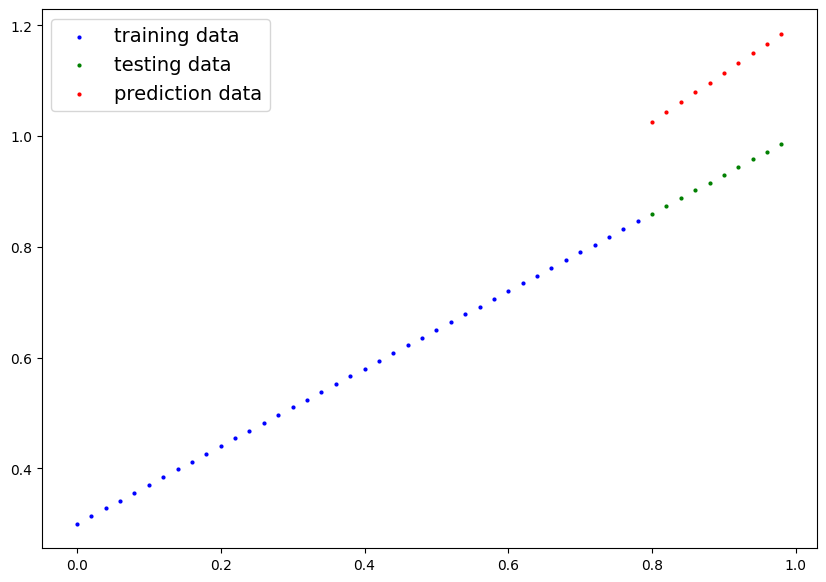

In [13]:
plot_predictions(predictions=y_preds)

 ## Train the model

 one way to measure how worng the predection of the model are si to use : **loss function** / cost function / criterion -> all are the same

 **Thins we need to train out model:**
 1. loss function
 2. Optimizer: takes into account the loss of the model and adjust the parameters (e.g., wieghts and bais) to improve the loss function

 in PyTorch we need:
 1. a tranign loop
 2. a testing loop

In [14]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.8823])),
             ('bais', tensor([0.3200], dtype=torch.float64))])

## Optimizers
we goona use mean absolute error `torch.nn.L1Loss`
There are mant on the documentation

In [15]:
## Set up a loss fun
loss_fn = torch.nn.L1Loss()

## set up an optemizer (stohastic greadint descent)
optimizer = torch.optim.SGD(params=model_0.parameters(), # Whcih parameters should the oprimizer update
                            lr=0.01, # Learnign rate, probably the most important parameter you set
                            )
# Hyperparameter: the paramrter the devolper set

### Create a traning loop (and a trainign loop)
0. look at teh data
1. Forword pass the data -> also called forward propagation -> to make predections
2. Calculate the loos (compare the predectinos to the graound truth)
3. optimze  zero grad
4. Loss backword (backpropagation)- move backwords through the network to calculate the gradeints of the parameters of our model  with respect to the loss
5. optemizer step - use the optimizer to djust out model paramters to try to imprive the loss
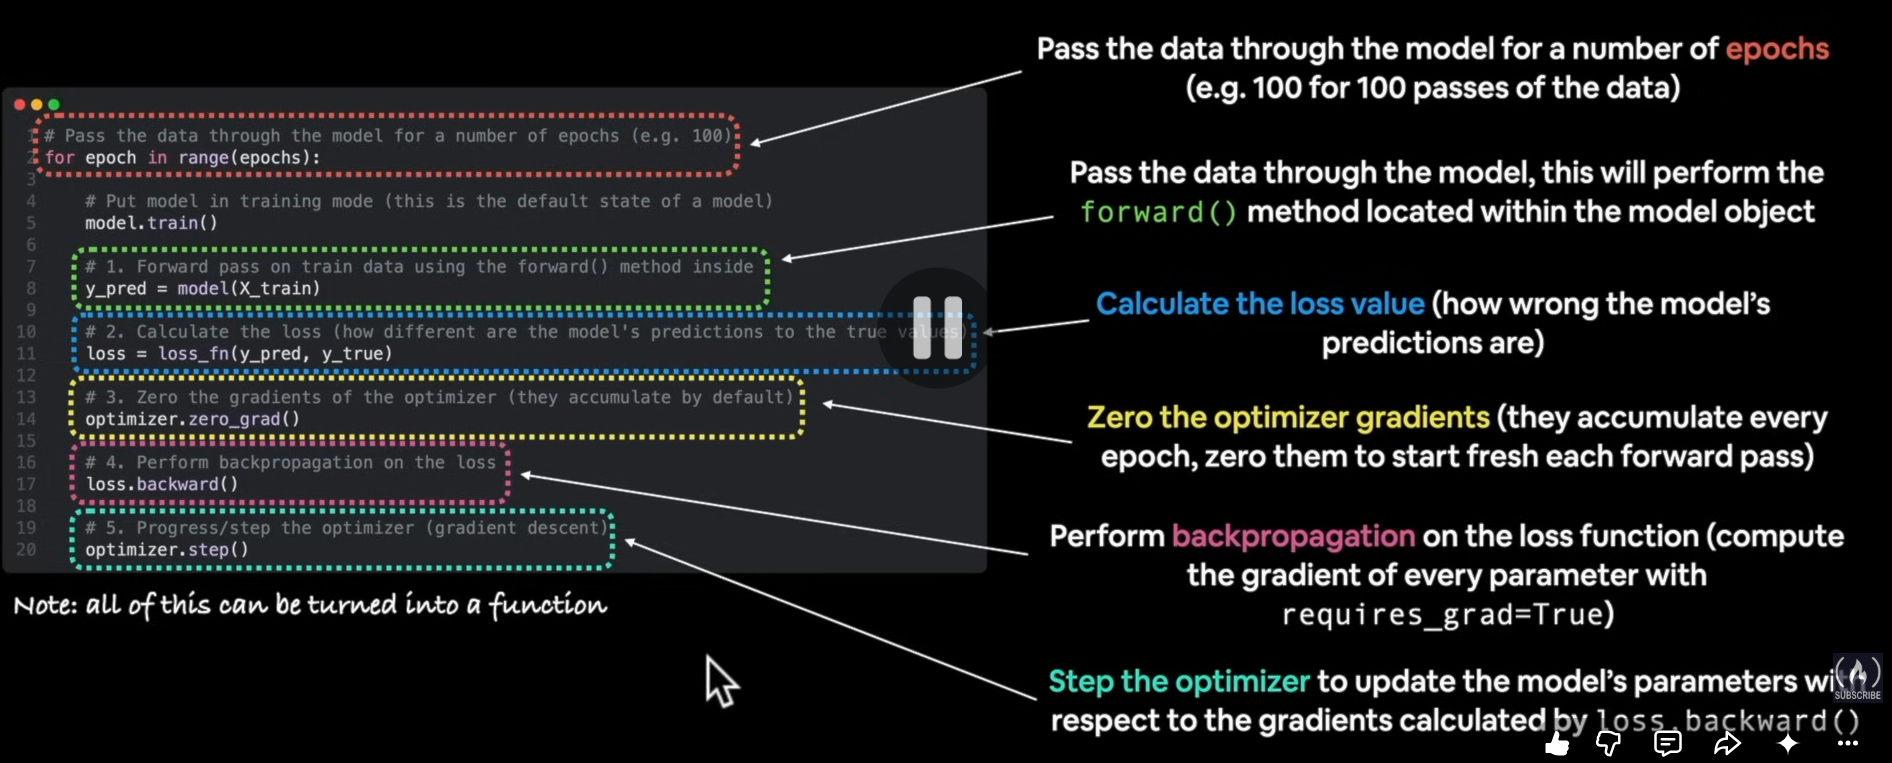

In [16]:
# epoch is one loop through th data

### Traning
# 0. Loop thriugh the data

epochs = 100 # hyperparameter
for epoch in range(epochs):
  # set the model in the trainign mode
  model_0.train() # set all paramrters that required gradients to `require_grad`

  # 1. forward pass
  y_preds = model_0(X_train)

  # 2. Calcualte loss
  loss = loss_fn(y_preds, y_train)
  # print(f"Loss: {loss}")

  # 3. optimizer zero grad
  # PyTorch accumulates gradients by default. This clears the gradients from the previous update so they don't mix with the new ones.
  # if in this  iteration optimizer calcuate to update by 1, we do not want to acculamte it for the next ones
  optimizer.zero_grad()

  # 4. perform backpropagationon the loss with respect to the parameters of the model
  # Calculates the gradients
  # It calculates how changing each weight or bias would affect the loss.
  loss.backward()

  # 5. perform the optimizer (perform gradint descent)
  # Update the parameters
  optimizer.step()

  # Testing
  model_0.eval() # turn off different settings in the mode not needed for testing/evalution
  with torch.inference_mode(): # turn off greident tracking a more
    test_preds = model_0(X_test)
    test_loss = loss_fn(test_preds, y_test)

    #print out what is happening
    if epoch % 10 == 0:
      print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")

  # print(model_0.state_dict())


Epoch: 0 | Loss: 0.09111710653242425 | Test Loss: 0.16878074680057123
Epoch: 10 | Loss: 0.0304422175291418 | Test Loss: 0.08028045998302051
Epoch: 20 | Loss: 0.025050087912859047 | Test Loss: 0.05918846593585565
Epoch: 30 | Loss: 0.02158568290966901 | Test Loss: 0.049542252642780095
Epoch: 40 | Loss: 0.01814960977307265 | Test Loss: 0.041956674677997366
Epoch: 50 | Loss: 0.014720861397044404 | Test Loss: 0.033684224230914814
Epoch: 60 | Loss: 0.01128204819179476 | Test Loss: 0.025411767823367803
Epoch: 70 | Loss: 0.007847650447885756 | Test Loss: 0.017826207739978495
Epoch: 80 | Loss: 0.004417225002789521 | Test Loss: 0.00955376325336057
Epoch: 90 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216


In [17]:
# Make predection
with torch.inference_mode():
  y_preds_new  = model_0(X_test)

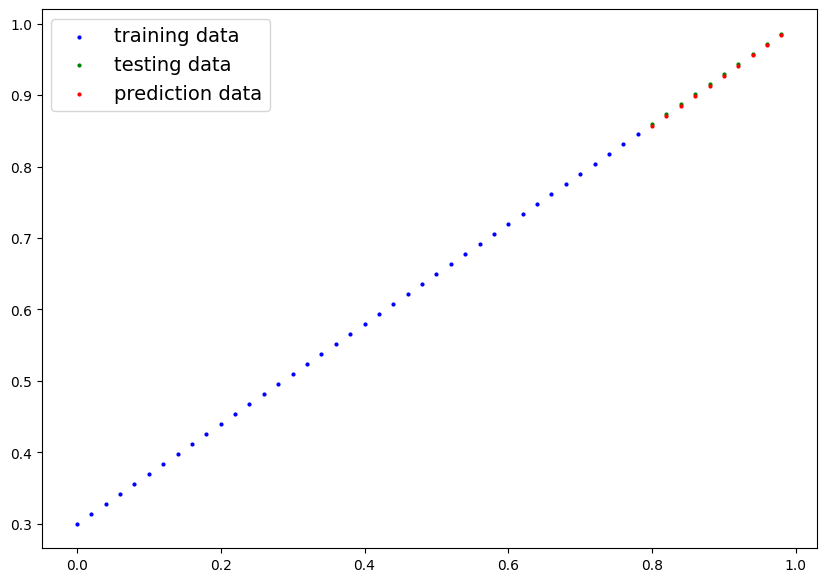

In [18]:
plot_predictions(predictions=y_preds_new)

# Store model progress (Tracking experimnts)

usful when we want to compare out current model with future one

In [19]:
epochs = 100

# Track diffrenet values
epoch_count = []
loss_values = []
test_loss_values = []

### Traning
for epoch in range(epochs):
  model_0.train()

  # 1. forward pass
  y_preds = model_0(X_train)

  # 2. Calcualte loss
  loss = loss_fn(y_preds, y_train)

  # 3. optimizer zero grad
  optimizer.zero_grad()

  # 4. perform backpropagationon
  loss.backward()

  # 5. perform the optimizer (perform gradint descent)
  optimizer.step()

  # Testing
  model_0.eval()
  with torch.inference_mode():
    test_preds = model_0(X_test)
    test_loss = loss_fn(test_preds, y_test)

    if epoch % 10 == 0:
      epoch_count.append(epoch)
      loss_values.append(loss)
      test_loss_values.append(test_loss)
      print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")

Epoch: 0 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216
Epoch: 10 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216
Epoch: 20 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216
Epoch: 30 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216
Epoch: 40 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216
Epoch: 50 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216
Epoch: 60 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216
Epoch: 70 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216
Epoch: 80 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216
Epoch: 90 | Loss: 0.0044745782234449916 | Test Loss: 0.010910949093967216


/tmp/ipykernel_410/947362515.py:5: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  loss_values_np = np.array(torch.tensor(loss_values).numpy())


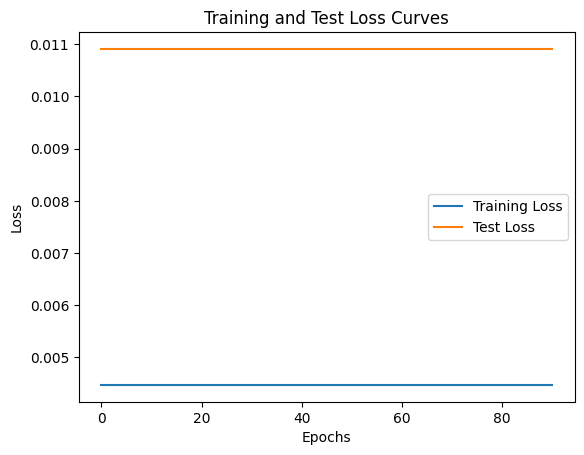

In [20]:
# plot the loss curve
import matplotlib.pyplot as plt
import numpy as np

loss_values_np = np.array(torch.tensor(loss_values).numpy())
plt.plot(epoch_count, loss_values_np, label="Training Loss")
plt.plot(epoch_count, test_loss_values, label="Test Loss")
plt.title("Training and Test Loss Curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()

# Something worng
it should be sth like this
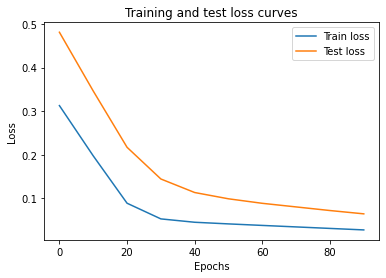

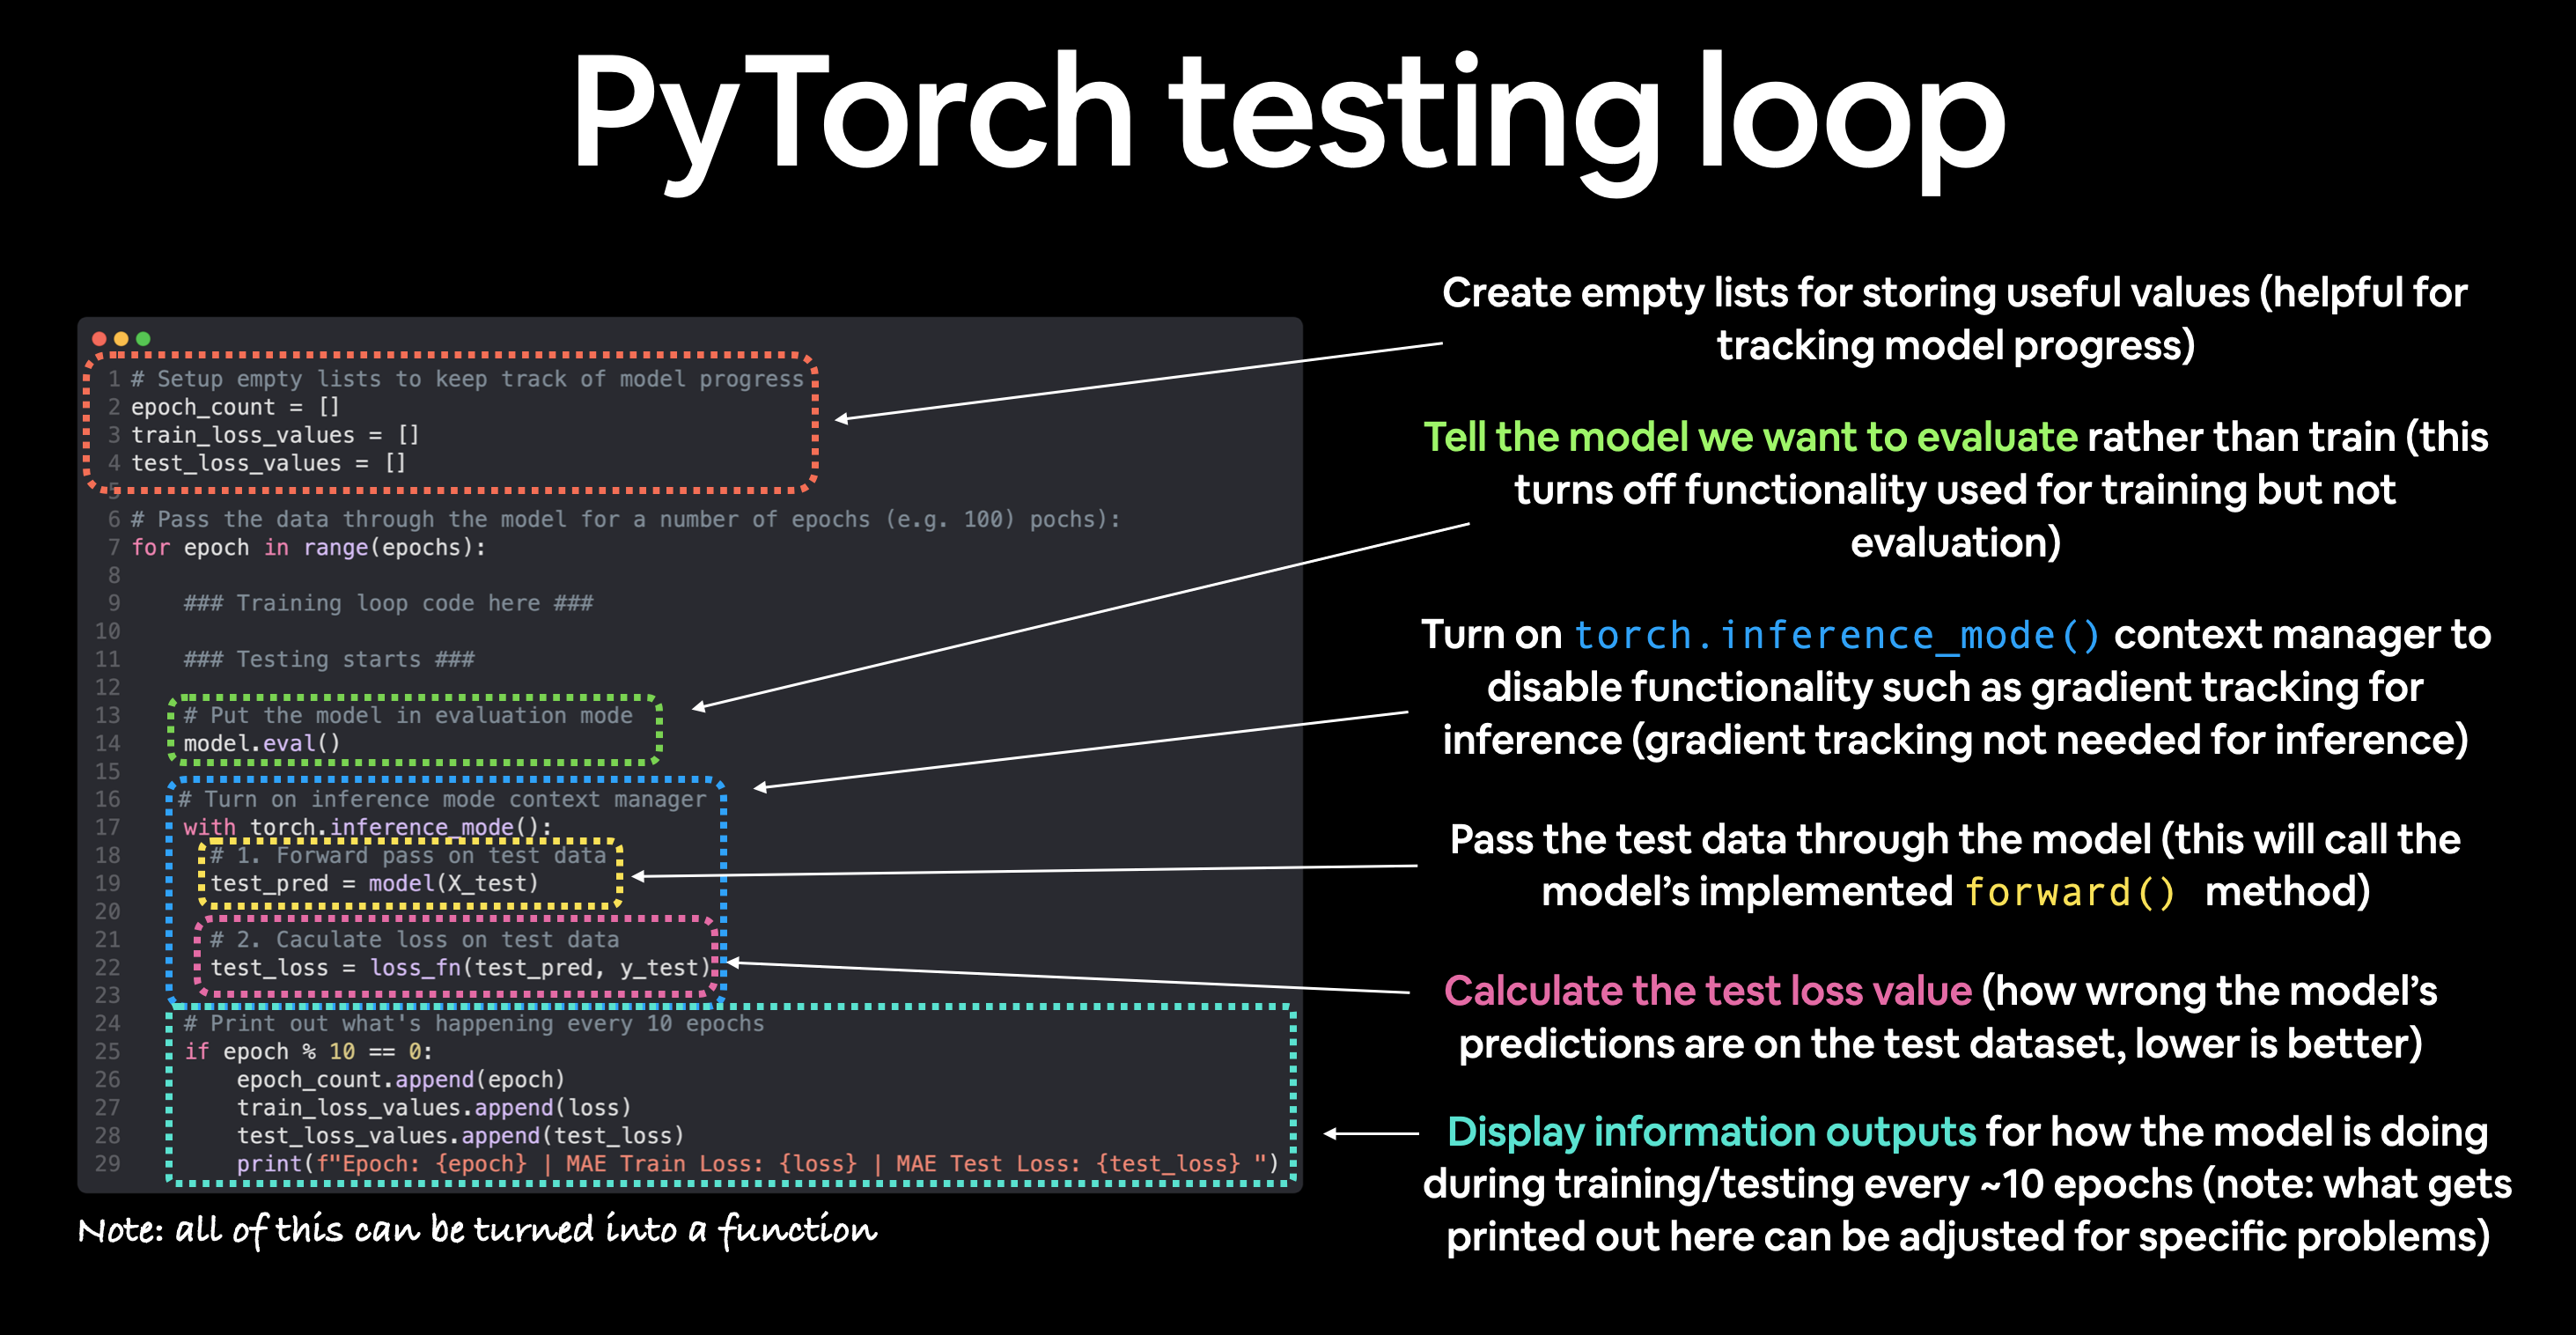

# Saving a model in PyTorch
Three mothods to save and load model in pytorch:
1. `torch.save()` -> save a PyTorch opj in python pickle formate (serializing formate)
2. `torch.load()` -> loadaa python obj
3. `torch.nn.Module.load_state_dict()` -> load a model's saved state dictionary

**The third is the recommended one**

> We can also save the entire model, see the doc, but saving #3 is the recemindded one

In [21]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.7038])),
             ('bais', tensor([0.2940], dtype=torch.float64))])

In [48]:
# Savign out pytorch model

from pathlib import Path
# python module for dealing with file path

# 1. create a model directory
# We can do it by hnad :) or:
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create a model save path
MODEL_NAME = "01_pytorch_workflow_model_0.pth"
# pytorch opjects has this extensiob : pth / pt

MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME # b. we use Path :)
MODEL_SAVE_PATH

# 3. save the model state_dict
print(f"Saving model to {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(),
           f=MODEL_SAVE_PATH)

Saving model to models/01_pytorch_workflow_model_0.pth


In [28]:
! ls -l models

total 4
-rw-r--r-- 1 root root 2181 Oct 19 14:21 01_pytorch_workflow_model_0.pth


# Loading out pytorch model

since we saved out model's `state_dict` instead of saving the entire model, we will create a new instance of our model class, and load the saved `state_dict` to it

In [32]:
# Create a new instance fro mthe model
loaded_model_0 = LinearRegressionModel()

# Load the saved state_dict -> this will upate the new instance with the new ipdated paeameters

print(f"The inital paramrters for the loaded model: \n{loaded_model_0.state_dict()}")

The inital paramrters for the loaded model: 
OrderedDict({'weights': tensor([0.1332]), 'bais': tensor([0.4768], dtype=torch.float64)})


In [35]:
loaded_state = torch.load(f=MODEL_SAVE_PATH,)
loaded_model_0.load_state_dict(loaded_state)

print(f"The UPDATED paramrters for the loaded model: \n{loaded_model_0.state_dict()}")
print(f"The original state dict: \n{model_0.state_dict()}")

The UPDATED paramrters for the loaded model: 
OrderedDict({'weights': tensor([0.7038]), 'bais': tensor([0.2940], dtype=torch.float64)})
The original state dict: 
OrderedDict({'weights': tensor([0.7038]), 'bais': tensor([0.2940], dtype=torch.float64)})


In [47]:
# Make a prediction with the 2 models

model_0.eval()

with torch.inference_mode():
  y_0_preds = model_0(X_test)


loaded_model_0.eval()

with torch.inference_mode():
  y_loaded_preds = loaded_model_0(X_test)

print(y_0_preds == y_loaded_preds)

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])
